# Лабораторна робота 3

**Тема:**
Розробити програмний засіб, який здійснює афінне перетворення множини точок заданих своїми координатами та відображує її на координатній площині і зберігає зображення в одному з графічних форматів.

**Виконав:** Бугайчук Василь 

**Група:** КМ-51

 

# Хід роботи

- Вивчити математичні основи афінних перетворень і особливості їх реалізації

- Використати датасет з лабораторної роботи №2

- Визначити афінне перетворенняяк обертання навколо точки (480; 480) на кут

- alpha degree equals 10 asterisk times left parenthesis n plus 1 right parenthesis space, де n відповідає останній цифрі логіну на платформу Сікорський (наприклад, km-95-019 – alpha equals 100 degree almost equal to 1 comma 745 space r a d). 

 і розрахувати його результуючу матрицю

- Скачати файл з датасетом. Файл в текстовому форматі містить пари цілих чисел які є координатами точок. 

# Необхідно написати програму будь якою мовою з використанням будь яких бібліотек яка

1. Зчитує датасет з файлу;
2. Виконує задане афінне перетворення з датасетом;
3. Встановлює розміри вікна (полотна – canvas size) 960х960 пкс;
4. Відображає  датасет після афінного перетворення точками синього кольору;
5. Виводить результати у файли будь-якого графічного формату

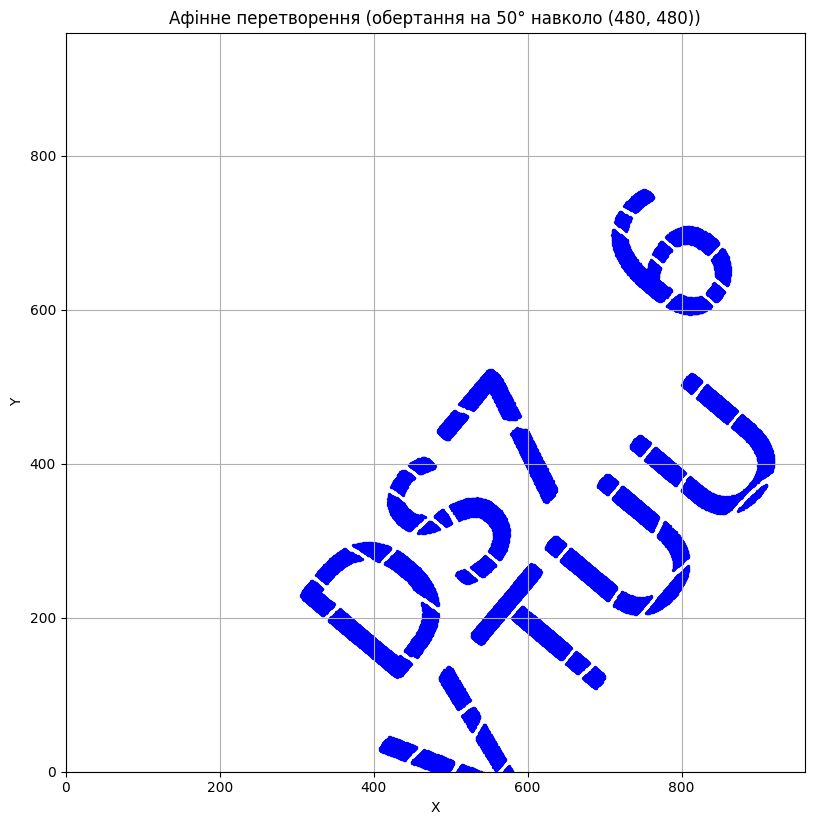

файл успішно збережено як {output_filename}


In [3]:
import math
import matplotlib.pyplot as plt

# 1. Зчитуємо датасет з файлу
file_path = r'D:\git\2 курс\CGM\лабораторна робота 2\DS7.txt'
with open(file_path, 'r') as file:
    data = file.read().splitlines()

x_coords = []
y_coords = []

for line in data:
    if line.strip():
        parts = line.split()
        if len(parts) >= 2:
            x_coords.append(float(parts[0]))
            y_coords.append(float(parts[1]))

# 2. Визначаємо параметри афінного перетворення (обертання навколо точки)
pivot_point = [480, 480]
xp, yp = pivot_point

# Обчислення кута (замініть 'n' на останню цифру вашого логіну, наприклад, якщо n=4: 10 * (4 + 1) = 50)
n = 4  # <-- Вкажіть тут вашу цифру n
angle_deg = 10 * (n + 1) 
angle_rad = math.radians(angle_deg)

cos_a = math.cos(angle_rad)
sin_a = math.sin(angle_rad)

# Застосовуємо формулу обертання навколо довільної точки (xp, yp) для кожного елемента датасету
new_x = []
new_y = []

for x, y in zip(x_coords, y_coords):
    x_transformed = (x - xp) * cos_a - (y - yp) * sin_a + xp
    y_transformed = (x - xp) * sin_a + (y - yp) * cos_a + yp
    new_x.append(x_transformed)
    new_y.append(y_transformed)

# 3. Встановлюємо розміри вікна (полотна) 960x960 пкс
# (9.6 дюймів на 9.6 дюймів при 100 DPI дає рівно 960x960 пікселів)
plt.figure(figsize=(9.6, 9.6), dpi=100)

# 4. Відображаємо датасет після афінного перетворення синього кольору
plt.scatter(new_x, new_y, color='blue', s=2)  # s - розмір точок

# Налаштування меж осей під розмір полотна
plt.xlim(0, 960)
plt.ylim(0, 960)
plt.gca().set_aspect('equal', adjustable='box')

plt.title(f"Афінне перетворення (обертання на {angle_deg}° навколо ({xp}, {yp}))")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# 5. Виводимо результати у файл графічного формату (наприклад, PNG)
output_filename = 'transformed_result.png'
plt.savefig(output_filename, dpi=100, bbox_inches='tight')

# Показуємо графік
plt.show()
print("файл успішно збережено як {output_filename}")